# inputDataMap v6 (261031) — 발표자료 슬라이드 6용 입력 데이터 지도

| 항목 | 내용 |
| --- | --- |
| 작성 일자 | 2026-10-31 |
| 용도 | 논문 2.2절 「가중 점수 기반 경로 추천」의 입력 데이터 2종을 한 장의 지도로 표시한다. 발표자료 전용 저자 작성 그림이며 논문에는 없다 |
| 버전 | v6 — 논문 표 1을 산출한 `avoidZoneTest_v6_260827`과 같은 입력 파일을 쓴다 |
| 외부 호출 | 배경 지도 타일만 받는다. Tmap은 호출하지 않는다 |
| 산출물 | `./output_inputmap_v6_261031/fig_slide6_input_map_v6_261031.png` (6.9 × 7.4in, 300dpi = 2070 × 2220px) |

## 1. 그림 구성

| 요소 | 표현 |
| --- | --- |
| 배경 지도 | 회색조 타일. 받은 타일을 회색조로 변환하고 옅게 처리한다 |
| CCTV 설치 지점 | 검정 점 (흰색 얇은 테두리로 겹침 구분) |
| 회피 구간 | 회색 반투명 면 |
| 강화군 | 삽입 지도로 분리. 점을 가리지 않는 모서리를 자동으로 고른다 |
| 군구 이름 | 점보다 아래 층에 표기하여 점을 가리지 않는다 |
| 범례·출처 | 지도 아래 띠에 표기. 개수는 데이터에서 직접 센다 |
| 축척·방위 | 삽입 지도와 겹치지 않는 모서리에 배치. 축척은 위도 보정(메르카토르 → 실제 거리)을 적용한다 |

## 2. 정적 이미지를 고른 이유

folium HTML을 캡처하는 방식 대신 matplotlib 정적 이미지를 택하였다.

| 기준 | matplotlib (본 노트북) | folium 캡처 |
| --- | --- | --- |
| 해상도 | 300dpi로 직접 저장 | 화면 해상도에 묶인다. 2070px 폭을 얻으려면 확대 캡처가 필요하다 |
| 재현성 | 타일을 캐시에 저장하여 재실행 시 같은 그림 | 캡처 시점·창 크기·타일 로딩에 따라 달라진다 |
| 크기 고정 | 6.9 × 7.4in로 고정 | 캡처 후 자르기 필요 |
| 축척·방위·삽입 지도 | 코드로 배치 | 별도 편집 필요 |

배경 타일은 contextily를 거치지 않고 직접 받는다. 요청 헤더를 통제할 수 있고, 캐시가 남아 같은 입력이면 같은 그림이 나온다.

## 3. 배경 지도 순서

| 순서 | 배경 | 조건 |
| --- | --- | --- |
| 1 | V-World 회색지도 | `.env`의 `VWORLD_KEY` 필요. 한글 지명이 표기된다 |
| 2 | Esri World Light Gray Canvas | 키 불필요. 지명 없음 |
| 3 | CARTO Positron | 키 불필요 |

앞의 것이 실패하면 자동으로 다음으로 넘어가며, 실제로 쓴 배경의 저작권 문구가 그림 하단에 들어간다.
V-World가 실패하면 키 발급 시 등록한 도메인을 `.env`에 `VWORLD_REFERER=https://등록도메인` 으로 넣고 다시 실행한다.

## 4. 실행 전 준비

v6 노트북과 같은 폴더에서 실행한다.

```
./hotspots_CCTV_20260510.csv
./output/incheon_avoid_zones_v1_260601.geojson   (또는 노트북과 같은 폴더)
./.env  →  VWORLD_KEY=...                         (선택)
```

필요 패키지: `pandas numpy shapely matplotlib pillow requests python-dotenv`. contextily는 필요 없다.

## 5. 실행 순서

셀 1부터 8까지 순서대로 실행한다. 셀 4의 출력을 보고 출처 문구를 확정한 뒤, 필요하면 셀 2의 `CCTV_SOURCE_TEXT`에 직접 적고 다시 실행한다. 셀 8 하단의 `[검증]`이 모두 통과인지 확인한다.


In [1]:
# 셀 1: 라이브러리 import 및 한글 글꼴 지정
# 배경 지도 타일은 contextily를 쓰지 않고 requests로 직접 받아 붙인다.
# 요청 헤더와 캐시를 직접 통제하여, 같은 입력이면 같은 그림이 나오게 하기 위함이다.

import os
import io
import json
import math
import time
from pathlib import Path

import numpy as np
import pandas as pd
import requests
from PIL import Image

from shapely.geometry import shape, Point, box
from shapely.ops import transform as shp_transform

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib import font_manager as fm
from matplotlib.patches import PathPatch, Patch, Rectangle, Polygon as MplPolygon
from matplotlib.path import Path as MplPath
from matplotlib.lines import Line2D

try:
    from dotenv import load_dotenv
    load_dotenv(override=True)
except ImportError:
    print("[안내] python-dotenv가 없어 .env를 읽지 않는다. VWORLD_KEY는 환경변수로만 읽는다.")

# --- 한글 글꼴: 운영체제별 후보를 순서대로 찾는다 ---
FONT_CANDIDATES = [
    "Malgun Gothic",        # Windows
    "AppleGothic",          # macOS
    "NanumGothic",          # 나눔고딕 설치 환경
    "Noto Sans CJK KR", "Noto Sans KR", "Noto Sans CJK JP",
]
_installed = {f.name for f in fm.fontManager.ttflist}
KFONT = next((f for f in FONT_CANDIDATES if f in _installed), None)
if KFONT is None:
    raise RuntimeError("한글 글꼴을 찾지 못했다. 맑은 고딕 또는 나눔고딕을 설치한 뒤 커널을 재시작한다.")

mpl.rcParams["font.family"] = KFONT
mpl.rcParams["axes.unicode_minus"] = False
mpl.rcParams["pdf.fonttype"] = 42

print("[셀 1 완료]")
print(f"  한글 글꼴   {KFONT}")
print(f"  matplotlib  {mpl.__version__}")
print(f"  작업 폴더   {Path.cwd()}")


[셀 1 완료]
  한글 글꼴   Malgun Gothic
  matplotlib  3.10.9
  작업 폴더   c:\Users\User\Documents\GitHub\ploggo-algorithm-test


In [9]:
# 셀 2: 입력 경로와 출력 설정
# 경로가 다르면 이 셀만 수정한다.

# --- 입력 ---
CSV_PATH = Path("./hotspots_CCTV_20260510.csv")
GEOJSON_CANDIDATES = [
    Path("./output/incheon_avoid_zones_v1_260601.geojson"),   # v6·v10 노트북과 같은 위치
    Path("./incheon_avoid_zones_v1_260601.geojson"),
]
GEOJSON_PATH = next((p for p in GEOJSON_CANDIDATES if p.exists()), GEOJSON_CANDIDATES[0])

EXPECTED_CCTV  = 1535      # 논문 기재값. 다르면 경고만 하고 실제 개수로 그린다
EXPECTED_ZONES = 147

# --- 출력 ---
STAMP     = "261031"
OUT_DIR   = Path(f"./output_inputmap_v6_{STAMP}")
CACHE_DIR = OUT_DIR / "tile_cache"        # 받은 타일을 저장해 두고 재실행 시 재사용한다
OUT_PNG   = OUT_DIR / f"fig_slide6_input_map_v6_{STAMP}.png"
OUT_DIR.mkdir(parents=True, exist_ok=True)

FIG_W_IN, FIG_H_IN = 6.9, 7.4       # 슬라이드 영역 (세로형)
DPI = 300                          # 2070 x 2220 px

# --- 배경 지도 ---
# 앞에서부터 시도하고, 실패하면 다음 것으로 넘어간다. 받은 타일은 모두 회색조로 변환한다.
BASEMAP_ORDER = ["vworld_gray", "esri_lightgray", "carto_positron"]
VWORLD_KEY     = os.getenv("VWORLD_KEY")
VWORLD_REFERER = os.getenv("VWORLD_REFERER")   # 키 발급 시 등록한 도메인. 없으면 비워 둔다
TILE_ZOOM_MAIN  = None    # None이면 출력 해상도에 맞춰 자동 결정. 지도 글자를 키우려면 12
TILE_ZOOM_INSET = None
TILE_FADE       = 0.25    # 0이면 원본 회색, 1이면 흰색. 점과 면이 도드라지도록 배경을 옅게 한다
MAX_MISSING_TILE_RATIO = 0.05

# --- 강화군 분리 ---
# 위치로 나눈다. 강화도·교동도·석모도 일대를 포함하는 상자다.
# 영종도(위도 약 37.54 이하)와 서구 검단(경도 126.60 이상)은 포함되지 않는다.
GANGHWA_BOX = dict(lon_max=126.58, lat_min=37.565)
INSET_CORNER = "auto"         # "auto" | "upper left" | "upper right" | "lower left" | "lower right"
INSET_WIDTH_FRACS = (0.36, 0.32, 0.28, 0.24)   # auto일 때 점을 가리지 않는 폭을 큰 것부터 찾는다

# --- 스타일 ---
CCTV_SIZE   = 5.0
CCTV_COLOR  = "#16A34A"    # 변경: black → 녹색
CCTV_EDGE   = "white"      # 유지. 녹색 점이 서로 겹칠 때 구분된다
CCTV_EDGE_W = 0.25
ZONE_FACE   = "#F87171"    # 변경: #4B5563 → 연한 빨강
ZONE_ALPHA  = 0.40         # 변경: 0.45 → 0.40. 아래 배경 지명이 비치도록 조금 낮춘다
ZONE_EDGE   = "#B91C1C"    # 변경: #1F2937 → 진한 빨강 테두리. 작은 폴리곤의 윤곽이 산다
ZONE_EDGE_W = 0.35
SHOW_DISTRICT_LABELS = True     # 군구 이름 표기. 점보다 아래 층에 그려 점을 가리지 않는다

# --- 출처 문구 (셀 4의 점검 결과를 보고 확정한다) ---
CCTV_SOURCE_TEXT = None

# 레이아웃 (그림 좌표 비율): 지도 영역과 하단 범례·출처 띠
MAP_RECT = [0.03, 0.145, 0.94, 0.84]    # left, bottom, width, height

print("[셀 2 완료]")
for p in (CSV_PATH, GEOJSON_PATH):
    print(f"  {'있음' if p.exists() else '없음'}  {p}")
print(f"  V-World 키  {'있음' if VWORLD_KEY else '없음 (Esri 회색지도로 대체)'}")
print(f"  출력        {OUT_PNG}  ({FIG_W_IN}x{FIG_H_IN}in, {DPI}dpi)")
missing = [p for p in (CSV_PATH, GEOJSON_PATH) if not p.exists()]
if missing:
    raise FileNotFoundError("입력 파일이 없다:\n  " + "\n  ".join(str(p.resolve()) for p in missing))


[셀 2 완료]
  있음  hotspots_CCTV_20260510.csv
  있음  output\incheon_avoid_zones_v1_260601.geojson
  V-World 키  있음
  출력        output_inputmap_v6_261031\fig_slide6_input_map_v6_261031.png  (6.9x7.4in, 300dpi)


In [3]:
# 셀 3: 데이터 로드와 무결성 점검
# 그림에 들어갈 개수가 논문 기재값과 같은지, 좌표가 인천 범위 안에 있는지 확인한다.

hotspots = pd.read_csv(CSV_PATH, encoding="utf-8-sig")

_need = ["hotspot_id", "latitude", "longitude", "source_district", "source_type", "cctv_count"]
_lack = [c for c in _need if c not in hotspots.columns]
if _lack:
    raise KeyError(f"CSV에 필요한 컬럼이 없다: {_lack}\n  실제 컬럼: {list(hotspots.columns)}")

print("=" * 72)
print("[CCTV 설치 지점]")
print("=" * 72)
print(f"  행 수            {len(hotspots):,}  (논문 {EXPECTED_CCTV:,})")
print(f"  카메라 합계      {int(hotspots['cctv_count'].sum()):,}대")

_nan = hotspots[["latitude", "longitude"]].isna().any(axis=1)
_out = ~hotspots["latitude"].between(37.0, 38.2) | ~hotspots["longitude"].between(125.9, 127.0)
_dup = hotspots["hotspot_id"].duplicated()
print(f"  좌표 결측        {int(_nan.sum())}")
print(f"  인천 범위 밖     {int((_out & ~_nan).sum())}")
print(f"  hotspot_id 중복  {int(_dup.sum())}")
if _nan.any() or (_out & ~_nan).any():
    print("  [경고] 결측·범위 밖 좌표는 지도에 표시할 수 없다. 아래 행을 확인한다.")
    print(hotspots.loc[_nan | _out, _need].head(10).to_string(index=False))
if len(hotspots) != EXPECTED_CCTV:
    print(f"  [경고] 논문 기재값 {EXPECTED_CCTV}과 다르다. 범례에는 실제 개수를 쓴다.")

print("\n  source_type")
print(hotspots["source_type"].value_counts().to_string())

# --- 회피 구간 ---
with open(GEOJSON_PATH, "r", encoding="utf-8") as f:
    _gj = json.load(f)

zones = []
n_fixed = 0
for feat in _gj["features"]:
    g = shape(feat["geometry"])
    if not g.is_valid:
        g = g.buffer(0)
        n_fixed += 1
    pr = feat.get("properties", {})
    zones.append({"geom": g, "uname": pr.get("uname"), "uqa_code": pr.get("uqa_code"),
                  "sigg_name": pr.get("sigg_name"), "dyear": pr.get("dyear")})

_zb = np.array([z["geom"].bounds for z in zones])
print("\n" + "=" * 72)
print("[회피 구간]")
print("=" * 72)
print(f"  폴리곤 수        {len(zones)}  (논문 {EXPECTED_ZONES})")
print(f"  좌표 범위        경도 {_zb[:,0].min():.3f}~{_zb[:,2].max():.3f}, "
      f"위도 {_zb[:,1].min():.3f}~{_zb[:,3].max():.3f}")
if not (124 < _zb[:, 0].min() and _zb[:, 2].max() < 132):
    raise ValueError("회피 구간 좌표가 경위도(WGS84)가 아니다. 좌표계를 확인한다.")
print(f"  형상 보정        {n_fixed}개 (자기교차 등)")
_zdf = pd.DataFrame(zones)
print("\n  용도지역")
print(_zdf.groupby(["uqa_code", "uname"]).size().to_string())
print("\n  군구")
print(_zdf["sigg_name"].value_counts().to_string())
if len(zones) != EXPECTED_ZONES:
    print(f"  [경고] 논문 기재값 {EXPECTED_ZONES}과 다르다. 범례에는 실제 개수를 쓴다.")

hotspots = hotspots[~_nan].copy()
N_CCTV, N_ZONES = len(hotspots), len(zones)
print(f"\n[셀 3 완료] 표시 대상 CCTV {N_CCTV:,}곳, 회피 구간 {N_ZONES}개")


[CCTV 설치 지점]
  행 수            1,535  (논문 1,535)
  카메라 합계      1,838대
  좌표 결측        0
  인천 범위 밖     0
  hotspot_id 중복  0

  source_type
source_type
district_file        940
national_standard    595

[회피 구간]
  폴리곤 수        147  (논문 147)
  좌표 범위        경도 126.471~126.766, 위도 37.342~37.768
  형상 보정        0개 (자기교차 등)

  용도지역
uqa_code  uname 
UQA310    전용공업지역     5
UQA320    일반공업지역    46
UQA330    준공업지역     96

  군구
sigg_name
서구      44
중구      29
미추홀구    15
남동구     14
동구      12
계양구     12
연수구     11
부평구      7
강화군      3

[셀 3 완료] 표시 대상 CCTV 1,535곳, 회피 구간 147개


## 출처 문구 판단 기준

공공데이터포털은 **표준데이터**와 **파일데이터**를 서로 다른 유형으로 등록한다. 표준데이터는 `…/standard.do`, 파일데이터는 `…/fileData.do` 주소를 쓴다.

- 전국CCTV표준데이터: https://www.data.go.kr/data/15013094/standard.do
- 군구가 개별로 올린 CCTV 현황은 대개 `인천광역시 ○○구_…` 이름의 파일데이터다

판단 순서는 다음과 같다.

1. `district_file` 940곳을 받은 원본 페이지의 주소를 확인한다
2. 주소가 `fileData.do`이면 표준데이터 체계 밖의 자료다. 두 출처를 함께 적는다
3. 주소가 전국CCTV표준데이터 페이지이면 1,535곳 전체를 표준데이터로 적어도 된다

원본 주소를 확인하기 전에는 아래 셀이 자동으로 정하는 **두 출처 병기 문구**를 쓴다. 이 문구는 어느 경우에도 사실과 어긋나지 않는다.


In [10]:
# 셀 4: CCTV 출처 유형 점검 → 출처 문구 결정
# 논문은 1,535곳 전체를 "전국CCTV표준데이터"로 서술했다.
# CSV에는 source_type이 두 종류이므로, 군구별로 어떤 유형에서 왔는지 먼저 본다.

ct = pd.crosstab(hotspots["source_district"], hotspots["source_type"], margins=True, margins_name="합계")
print("[군구 × 출처 유형]")
print(ct.to_string())

# 출처를 더 자세히 적은 컬럼이 있으면 함께 보여준다
_extra = [c for c in hotspots.columns
          if any(k in c.lower() for k in ("source_file", "source_url", "dataset", "file", "url", "provider"))
          and c not in ("source_type", "source_district")]
for c in _extra:
    print(f"\n[{c}] 상위 값")
    print(hotspots[c].value_counts().head(15).to_string())

_by = hotspots.groupby("source_district")["source_type"].agg(lambda s: set(s))
only_file = [d for d, s in _by.items() if s == {"district_file"}]
only_std  = [d for d, s in _by.items() if s == {"national_standard"}]
mixed     = [d for d, s in _by.items() if len(s) > 1]
print("\n[해석]")
print(f"  표준데이터만     {only_std}")
print(f"  군구 파일만      {only_file}")
print(f"  두 유형 혼합     {mixed}")

n_std  = int((hotspots["source_type"] == "national_standard").sum())
n_file = int((hotspots["source_type"] == "district_file").sum())

# 공공데이터포털은 '표준데이터'(standard.do)와 '파일데이터'(fileData.do)를 별도 유형으로 등록한다.
# 군구 개별 파일이 표준데이터 페이지에 실려 있지 않다면 표준데이터 체계 밖의 자료다.
# 아래 문구는 어느 경우에도 사실과 어긋나지 않는다. 확정 후 필요하면 직접 고친다.
if CCTV_SOURCE_TEXT is None:
    if n_file == 0:
        CCTV_SOURCE_TEXT = "전국CCTV표준데이터(공공데이터포털)"
    else:
        CCTV_SOURCE_TEXT = "전국CCTV표준데이터 및 인천 군구별 CCTV 현황 파일데이터(공공데이터포털)"

print(f"\n  표준데이터 {n_std}곳 / 군구 파일 {n_file}곳")
print(f"  출처 문구 → {CCTV_SOURCE_TEXT}")


[군구 × 출처 유형]
source_type      district_file  national_standard    합계
source_district                                        
bupyeong                    42                  0    42
donggu                      48                  0    48
ganghwa                     86                  0    86
gyeyang                      0                292   292
junggu                       0                 74    74
michuhol                   230                  0   230
namdong                    155                  0   155
seogu                      379                  0   379
yeonsu                       0                229   229
합계                         940                595  1535

[해석]
  표준데이터만     ['gyeyang', 'junggu', 'yeonsu']
  군구 파일만      ['bupyeong', 'donggu', 'ganghwa', 'michuhol', 'namdong', 'seogu']
  두 유형 혼합     []

  표준데이터 595곳 / 군구 파일 940곳
  출처 문구 → 전국CCTV표준데이터 및 인천 군구별 CCTV 현황 파일데이터(공공데이터포털)


In [5]:
# 셀 5: 좌표 변환(웹 메르카토르) + 본 지도 / 강화군 삽입 지도 분리 + 화면 범위 산정
# 배경 타일이 웹 메르카토르(EPSG:3857)이므로 점과 면도 같은 좌표로 바꿔 그린다.

R_EARTH = 6378137.0
ORIGIN  = math.pi * R_EARTH          # 20,037,508.34 m


def to_merc(lon, lat):
    lon = np.asarray(lon, dtype=float)
    lat = np.clip(np.asarray(lat, dtype=float), -85.0, 85.0)
    return R_EARTH * np.radians(lon), R_EARTH * np.log(np.tan(np.pi / 4 + np.radians(lat) / 2))


def merc_to_lat(y):
    return math.degrees(2 * math.atan(math.exp(y / R_EARTH)) - math.pi / 2)


def geom_to_merc(g):
    try:
        import shapely
        return shapely.transform(g, lambda c: np.column_stack(to_merc(c[:, 0], c[:, 1])))
    except AttributeError:          # shapely 1.x
        return shp_transform(lambda x, y, z=None: to_merc(x, y), g)


# --- 위치 기준 분리 ---
_in_gh = ((hotspots["longitude"] < GANGHWA_BOX["lon_max"]) &
          (hotspots["latitude"] > GANGHWA_BOX["lat_min"]))
hotspots["region"] = np.where(_in_gh, "inset", "main")
hotspots["mx"], hotspots["my"] = to_merc(hotspots["longitude"], hotspots["latitude"])

# 라벨과 위치가 어긋나는 점을 보고한다 (그림은 위치 기준으로 배치한다)
_lab_gh = hotspots["source_district"].eq("ganghwa")
_mis1 = hotspots[_in_gh & ~_lab_gh]
_mis2 = hotspots[~_in_gh & _lab_gh]
print("[분리 결과 — 위치 기준]")
print(f"  본 지도   {int((~_in_gh).sum()):,}곳")
print(f"  삽입 지도 {int(_in_gh.sum()):,}곳 (강화군)")
print(f"  합계      {len(hotspots):,}곳")
if len(_mis1) or len(_mis2):
    print(f"  [확인] 강화 상자 안인데 라벨이 강화가 아닌 점 {len(_mis1)}곳, "
          f"라벨은 강화인데 상자 밖인 점 {len(_mis2)}곳")
    print(pd.concat([_mis1, _mis2])[["hotspot_id", "source_district", "latitude", "longitude"]]
          .head(10).to_string(index=False))

for z in zones:
    c = z["geom"].representative_point()
    z["region"] = "inset" if (c.x < GANGHWA_BOX["lon_max"] and c.y > GANGHWA_BOX["lat_min"]) else "main"
    z["mgeom"] = geom_to_merc(z["geom"])
print(f"  회피 구간 본 지도 {sum(z['region'] == 'main' for z in zones)}개 / "
      f"삽입 지도 {sum(z['region'] == 'inset' for z in zones)}개")


def data_bounds(region):
    pts = hotspots[hotspots["region"] == region]
    xs = list(pts["mx"]); ys = list(pts["my"])
    for z in zones:
        if z["region"] == region:
            b = z["mgeom"].bounds
            xs += [b[0], b[2]]; ys += [b[1], b[3]]
    if not xs:
        return None
    return [min(xs), max(xs), min(ys), max(ys)]


def pad_extent(ext, frac):
    dx, dy = ext[1] - ext[0], ext[3] - ext[2]
    return [ext[0] - dx * frac, ext[1] + dx * frac, ext[2] - dy * frac, ext[3] + dy * frac]


def fit_aspect(ext, h_over_w):
    """화면 비율에 맞도록 짧은 쪽을 양옆으로 넓힌다 (데이터는 잘리지 않는다)."""
    x0, x1, y0, y1 = ext
    w, h = x1 - x0, y1 - y0
    if h / w < h_over_w:
        nh = w * h_over_w; cy = (y0 + y1) / 2
        return [x0, x1, cy - nh / 2, cy + nh / 2]
    nw = h / h_over_w; cx = (x0 + x1) / 2
    return [cx - nw / 2, cx + nw / 2, y0, y1]


MAP_W_IN = FIG_W_IN * MAP_RECT[2]
MAP_H_IN = FIG_H_IN * MAP_RECT[3]
EXT_MAIN = fit_aspect(pad_extent(data_bounds("main"), 0.04), MAP_H_IN / MAP_W_IN)
EXT_INSET_DATA = data_bounds("inset")
EXT_INSET = pad_extent(EXT_INSET_DATA, 0.06) if EXT_INSET_DATA else None


def ground_km(ext):
    lat = merc_to_lat((ext[2] + ext[3]) / 2)
    k = math.cos(math.radians(lat))
    return (ext[1] - ext[0]) * k / 1000, (ext[3] - ext[2]) * k / 1000


print(f"\n[화면 범위] 본 지도 약 {ground_km(EXT_MAIN)[0]:.1f} x {ground_km(EXT_MAIN)[1]:.1f} km")
if EXT_INSET:
    print(f"            삽입 지도 약 {ground_km(EXT_INSET)[0]:.1f} x {ground_km(EXT_INSET)[1]:.1f} km")


[분리 결과 — 위치 기준]
  본 지도   1,449곳
  삽입 지도 86곳 (강화군)
  합계      1,535곳
  회피 구간 본 지도 144개 / 삽입 지도 3개

[화면 범위] 본 지도 약 36.9 x 35.3 km
            삽입 지도 약 16.3 x 28.3 km


In [6]:
# 셀 6: 배경 지도 타일 받기 (회색조 변환 + 캐시)
# 받은 타일은 CACHE_DIR에 저장된다. 다시 실행하면 저장본을 쓰므로 같은 그림이 나온다.
# 다른 배경으로 바꾸려면 BASEMAP_ORDER의 순서를 바꾼다.

TILE_SOURCES = {
    "vworld_gray": dict(
        url=lambda z, x, y: f"https://api.vworld.kr/req/wmts/1.0.0/{VWORLD_KEY}/gray/{z}/{y}/{x}.png",
        enabled=lambda: bool(VWORLD_KEY), max_zoom=18,
        credit="V-World 회색지도 (국토교통부)"),
    "esri_lightgray": dict(
        url=lambda z, x, y: ("https://server.arcgisonline.com/ArcGIS/rest/services/"
                             f"Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}"),
        enabled=lambda: True, max_zoom=16,
        credit="Esri World Light Gray Canvas (© Esri, HERE, Garmin, © OpenStreetMap contributors)"),
    "carto_positron": dict(
        url=lambda z, x, y: f"https://basemaps.cartocdn.com/light_all/{z}/{x}/{y}.png",
        enabled=lambda: True, max_zoom=19,
        credit="CARTO Positron (© OpenStreetMap contributors © CARTO)"),
}
# V-World는 좌표 순서가 {z}/{y}/{x}다. Esri도 같고, CARTO만 {z}/{x}/{y}다.

_HEADERS = {"User-Agent": "Mozilla/5.0 (Ploggo research figure)"}


def tile_size_m(z):
    return 2 * ORIGIN / (2 ** z)


def auto_zoom(ext, out_px, max_zoom):
    for z in range(8, max_zoom + 1):
        if (ext[1] - ext[0]) / tile_size_m(z) * 256 >= out_px:
            return z
    return max_zoom


def tile_range(ext, z):
    s = tile_size_m(z); n = 2 ** z
    tx0 = int((ext[0] + ORIGIN) // s); tx1 = int((ext[1] + ORIGIN) // s)
    ty0 = int((ORIGIN - ext[3]) // s); ty1 = int((ORIGIN - ext[2]) // s)
    return max(tx0, 0), min(tx1, n - 1), max(ty0, 0), min(ty1, n - 1)


def _get_tile(src_key, z, x, y):
    """캐시 우선. 실패하면 None."""
    path = CACHE_DIR / src_key / str(z) / str(x) / f"{y}.png"
    if path.exists():
        try:
            return Image.open(path).convert("RGB")
        except Exception:
            path.unlink(missing_ok=True)
    headers = dict(_HEADERS)
    if src_key == "vworld_gray" and VWORLD_REFERER:
        headers["Referer"] = VWORLD_REFERER
    try:
        r = requests.get(TILE_SOURCES[src_key]["url"](z, x, y), headers=headers, timeout=10)
    except Exception:
        return None
    if r.status_code != 200 or not r.headers.get("Content-Type", "").startswith("image"):
        return None
    try:
        img = Image.open(io.BytesIO(r.content)).convert("RGB")
    except Exception:
        return None
    path.parent.mkdir(parents=True, exist_ok=True)
    img.save(path)
    time.sleep(0.02)
    return img


def fetch_basemap(ext, out_px, zoom=None, label=""):
    """BASEMAP_ORDER 순서로 시도. 성공하면 (회색조 배열, 모자이크 범위, 출처 문구)를 돌려준다."""
    for key in BASEMAP_ORDER:
        src = TILE_SOURCES[key]
        if not src["enabled"]():
            print(f"  [{label}] {key} 건너뜀 (인증키 없음)")
            continue
        z = min(zoom or auto_zoom(ext, out_px, src["max_zoom"]), src["max_zoom"])
        tx0, tx1, ty0, ty1 = tile_range(ext, z)
        n_tiles = (tx1 - tx0 + 1) * (ty1 - ty0 + 1)

        # 첫 타일로 접속 가능 여부를 먼저 본다 (막힌 서버에서 시간을 쓰지 않기 위함)
        if _get_tile(key, z, tx0, ty0) is None:
            print(f"  [{label}] {key} 접속 실패 → 다음 배경으로")
            continue

        mosaic = Image.new("RGB", ((tx1 - tx0 + 1) * 256, (ty1 - ty0 + 1) * 256), "white")
        miss = 0
        for tx in range(tx0, tx1 + 1):
            for ty in range(ty0, ty1 + 1):
                im = _get_tile(key, z, tx, ty)
                if im is None:
                    miss += 1
                    continue
                mosaic.paste(im.resize((256, 256)), ((tx - tx0) * 256, (ty - ty0) * 256))
        if miss / n_tiles > MAX_MISSING_TILE_RATIO:
            print(f"  [{label}] {key} 타일 {miss}/{n_tiles}장 누락 → 다음 배경으로")
            continue

        gray = np.asarray(mosaic.convert("L"), dtype=float)          # ITU-R 601 휘도
        gray = gray * (1 - TILE_FADE) + 255 * TILE_FADE
        s = tile_size_m(z)
        mext = [-ORIGIN + tx0 * s, -ORIGIN + (tx1 + 1) * s,
                ORIGIN - (ty1 + 1) * s, ORIGIN - ty0 * s]
        print(f"  [{label}] {key} 사용 — 줌 {z}, 타일 {n_tiles}장 (누락 {miss})")
        return gray.astype(np.uint8), mext, src["credit"]

    print(f"  [{label}] [경고] 모든 배경 지도가 실패했다. 흰 배경으로 그린다.")
    return None, None, None


print("[배경 지도 받기]")
_px_main = int(FIG_W_IN * MAP_RECT[2] * DPI)
BG_MAIN = fetch_basemap(EXT_MAIN, _px_main, TILE_ZOOM_MAIN, "본 지도")
BG_INSET = (fetch_basemap(EXT_INSET, int(_px_main * max(INSET_WIDTH_FRACS)), TILE_ZOOM_INSET, "삽입 지도")
            if EXT_INSET else (None, None, None))
BASEMAP_CREDIT = BG_MAIN[2] or BG_INSET[2]
if BG_INSET[2] and BG_MAIN[2] and BG_INSET[2] != BG_MAIN[2]:
    print("  [확인] 본 지도와 삽입 지도의 배경 출처가 다르다. 출처 문구에 둘 다 적는다.")
    BASEMAP_CREDIT = f"{BG_MAIN[2]} / 삽입: {BG_INSET[2]}"
print(f"  배경 출처 → {BASEMAP_CREDIT or '없음'}")


[배경 지도 받기]
  [본 지도] vworld_gray 접속 실패 → 다음 배경으로
  [본 지도] esri_lightgray 사용 — 줌 13, 타일 110장 (누락 0)
  [삽입 지도] vworld_gray 접속 실패 → 다음 배경으로
  [삽입 지도] esri_lightgray 사용 — 줌 13, 타일 45장 (누락 0)
  배경 출처 → Esri World Light Gray Canvas (© Esri, HERE, Garmin, © OpenStreetMap contributors)


In [7]:
# 셀 7: 그리기 도구 — 레이어, 축척 막대, 방위 표시, 삽입 지도 위치 선정

KOR_DISTRICT = {
    "junggu": "중구", "donggu": "동구", "michuhol": "미추홀구", "yeonsu": "연수구",
    "namdong": "남동구", "bupyeong": "부평구", "gyeyang": "계양구", "seogu": "서구",
    "ganghwa": "강화군",
}
LABEL_OVERRIDE = {}     # 위치를 직접 지정하려면 {"junggu": (경도, 위도)} 형태로 넣는다

_HALO = [pe.withStroke(linewidth=2.2, foreground="white")]


def polys_to_patch(geoms, **kw):
    """여러 폴리곤을 하나의 PathPatch로 묶는다 (구멍 포함)."""
    verts, codes = [], []
    for g in geoms:
        parts = [g] if g.geom_type == "Polygon" else list(getattr(g, "geoms", []))
        for p in parts:
            if p.geom_type != "Polygon" or p.is_empty:
                continue
            for ring in [p.exterior, *p.interiors]:
                xy = np.asarray(ring.coords)
                verts.extend(xy.tolist())
                codes.extend([MplPath.MOVETO] + [MplPath.LINETO] * (len(xy) - 2) + [MplPath.CLOSEPOLY])
    return PathPatch(MplPath(verts, codes), **kw)


def draw_layers(ax, region, ext, bg):
    """배경 → 회피 구간 → (군구 이름) → CCTV 점 순서로 쌓는다. 그린 점 수를 돌려준다."""
    img, mext, _ = bg
    if img is not None:
        ax.imshow(img, extent=mext, cmap="gray", vmin=0, vmax=255,
                  interpolation="antialiased", zorder=0)
    else:
        ax.set_facecolor("white")

    zg = [z["mgeom"] for z in zones if z["region"] == region]
    if zg:
        ax.add_patch(polys_to_patch(zg, facecolor=ZONE_FACE, alpha=ZONE_ALPHA,
                                    edgecolor="none", zorder=2))
        ax.add_patch(polys_to_patch(zg, facecolor="none", edgecolor=ZONE_EDGE,
                                    linewidth=ZONE_EDGE_W, zorder=2.1))

    pts = hotspots[hotspots["region"] == region]
    ax.scatter(pts["mx"], pts["my"], s=CCTV_SIZE, c=CCTV_COLOR, edgecolors=CCTV_EDGE,
               linewidths=CCTV_EDGE_W, zorder=5, rasterized=False)

    ax.set_xlim(ext[0], ext[1]); ax.set_ylim(ext[2], ext[3])
    ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_linewidth(0.6); s.set_color("#111827")
    return len(pts)


def draw_district_labels(ax, region, fontsize=8.5):
    """군구 이름을 그 군구 CCTV 점들의 대표점(중앙값에 가장 가까운 실제 점)에 적는다.
    점보다 아래 층(zorder 3)이므로 점을 가리지 않는다."""
    pts = hotspots[hotspots["region"] == region]
    total = hotspots["source_district"].value_counts()
    for code, g in pts.groupby("source_district"):
        # 그 군구 점의 과반이 이 지도에 있을 때만 이름을 적는다 (경계 밖 소수 점 때문에 엉뚱한 곳에 찍히지 않게)
        if len(g) < 0.5 * total[code]:
            continue
        if code in LABEL_OVERRIDE:
            x, y = to_merc(*LABEL_OVERRIDE[code])
        else:
            mx, my = g["mx"].median(), g["my"].median()
            i = ((g["mx"] - mx) ** 2 + (g["my"] - my) ** 2).idxmin()
            x, y = g.at[i, "mx"], g.at[i, "my"]
        ax.text(x, y, KOR_DISTRICT.get(code, code), fontsize=fontsize, fontweight="bold",
                color="#111827", ha="center", va="center", path_effects=_HALO, zorder=3)


def nice_length_km(span_km, frac=0.22):
    target = span_km * frac
    for v in (0.5, 1, 2, 3, 5, 10, 20, 25, 50):
        if v >= target:
            return v
    return 50


def draw_scale_bar(ax, ext, corner="lower right", fontsize=7, frac=0.22, segs=4, margin=0.04):
    lat = merc_to_lat((ext[2] + ext[3]) / 2)
    k = math.cos(math.radians(lat))                 # 메르카토르 → 실제 거리 보정
    span_km = (ext[1] - ext[0]) * k / 1000
    L = nice_length_km(span_km, frac)
    Lm = L * 1000 / k
    dx, dy = ext[1] - ext[0], ext[3] - ext[2]
    h = dy * 0.010
    x0 = ext[0] + dx * margin if "left" in corner else ext[1] - dx * margin - Lm
    y0 = ext[2] + dy * 0.035 if "lower" in corner else ext[3] - dy * 0.07
    for i in range(segs):
        ax.add_patch(Rectangle((x0 + Lm * i / segs, y0), Lm / segs, h,
                               facecolor="black" if i % 2 == 0 else "white",
                               edgecolor="black", linewidth=0.5, zorder=8))
    for v, xx in ((0, x0), (L / 2, x0 + Lm / 2), (L, x0 + Lm)):
        t = f"{v:g}" if v != L else f"{v:g} km"
        ax.text(xx, y0 + h * 1.9, t, fontsize=fontsize, ha="center", va="bottom",
                path_effects=_HALO, zorder=8)
    return L


def draw_north_arrow(ax, corner="upper right", size=0.065):
    fx = 0.94 if "right" in corner else 0.06
    fy = 0.95 if "upper" in corner else 0.12
    w = size * 0.42
    tip, base_l, base_r, notch = (fx, fy), (fx - w / 2, fy - size), (fx + w / 2, fy - size), (fx, fy - size * 0.72)
    ax.add_patch(MplPolygon([tip, base_l, notch], closed=True, facecolor="black",
                            edgecolor="black", linewidth=0.6, transform=ax.transAxes, zorder=9))
    ax.add_patch(MplPolygon([tip, notch, base_r], closed=True, facecolor="white",
                            edgecolor="black", linewidth=0.6, transform=ax.transAxes, zorder=9))
    ax.text(fx, fy - size - 0.022, "N", transform=ax.transAxes, fontsize=9, fontweight="bold",
            ha="center", va="top", path_effects=_HALO, zorder=9)


def _frac_box_to_data(fx0, fy0, fw, fh, ext):
    dx, dy = ext[1] - ext[0], ext[3] - ext[2]
    return box(ext[0] + fx0 * dx, ext[2] + fy0 * dy, ext[0] + (fx0 + fw) * dx, ext[2] + (fy0 + fh) * dy)


def count_hidden(b):
    pts = hotspots[hotspots["region"] == "main"]
    xmin, ymin, xmax, ymax = b.bounds
    n_pts = int(((pts["mx"] >= xmin) & (pts["mx"] <= xmax) & (pts["my"] >= ymin) & (pts["my"] <= ymax)).sum())
    n_zone = sum(1 for z in zones if z["region"] == "main" and z["mgeom"].intersects(b))
    return n_pts, n_zone


CORNERS = ["upper left", "upper right", "lower left", "lower right"]   # 동률이면 북서쪽 우선


def inset_rect(corner, wfrac, margin=0.012):
    """본 지도 축 기준 비율 좌표 (x0, y0, w, h)."""
    aspect = (EXT_INSET[3] - EXT_INSET[2]) / (EXT_INSET[1] - EXT_INSET[0])
    fw = wfrac
    fh = fw * MAP_W_IN * aspect / MAP_H_IN
    if fh > 0.48:
        fh = 0.48
        fw = fh * MAP_H_IN / (MAP_W_IN * aspect)
    fx0 = margin if "left" in corner else 1 - margin - fw
    fy0 = 1 - margin - fh if "upper" in corner else margin
    return fx0, fy0, fw, fh


def choose_inset():
    """점을 하나도 가리지 않는 모서리와 폭을 찾는다. 없으면 가리는 점이 가장 적은 조합."""
    corners = CORNERS if INSET_CORNER == "auto" else [INSET_CORNER]
    best = None
    for wf in INSET_WIDTH_FRACS:
        for c in corners:
            r = inset_rect(c, wf)
            n_pts, n_zone = count_hidden(_frac_box_to_data(*r, EXT_MAIN))
            cand = (n_pts, n_zone, -wf, CORNERS.index(c), c, r)
            if best is None or cand[:4] < best[:4]:
                best = cand
        if best[0] == 0 and best[1] == 0:
            break
    return best


def free_corner(exclude, kind):
    """축척 막대(하단)·방위 표시(상단)를 둘 모서리. 삽입 지도와 겹치지 않고 가리는 점이 적은 쪽."""
    cands = [c for c in CORNERS if c != exclude and c.startswith("lower" if kind == "scale" else "upper")]
    if not cands:
        cands = [c for c in CORNERS if c != exclude]
    def hidden(c):
        if kind == "scale":
            r = (0.03, 0.02, 0.30, 0.07) if "left" in c else (0.67, 0.02, 0.30, 0.07)
        else:
            r = (0.02, 0.80, 0.08, 0.17) if "left" in c else (0.90, 0.80, 0.08, 0.17)
        return count_hidden(_frac_box_to_data(*r, EXT_MAIN))[0]
    return min(cands, key=lambda c: (hidden(c), CORNERS.index(c)))


print("[셀 7 완료] 그리기 도구 정의")


[셀 7 완료] 그리기 도구 정의


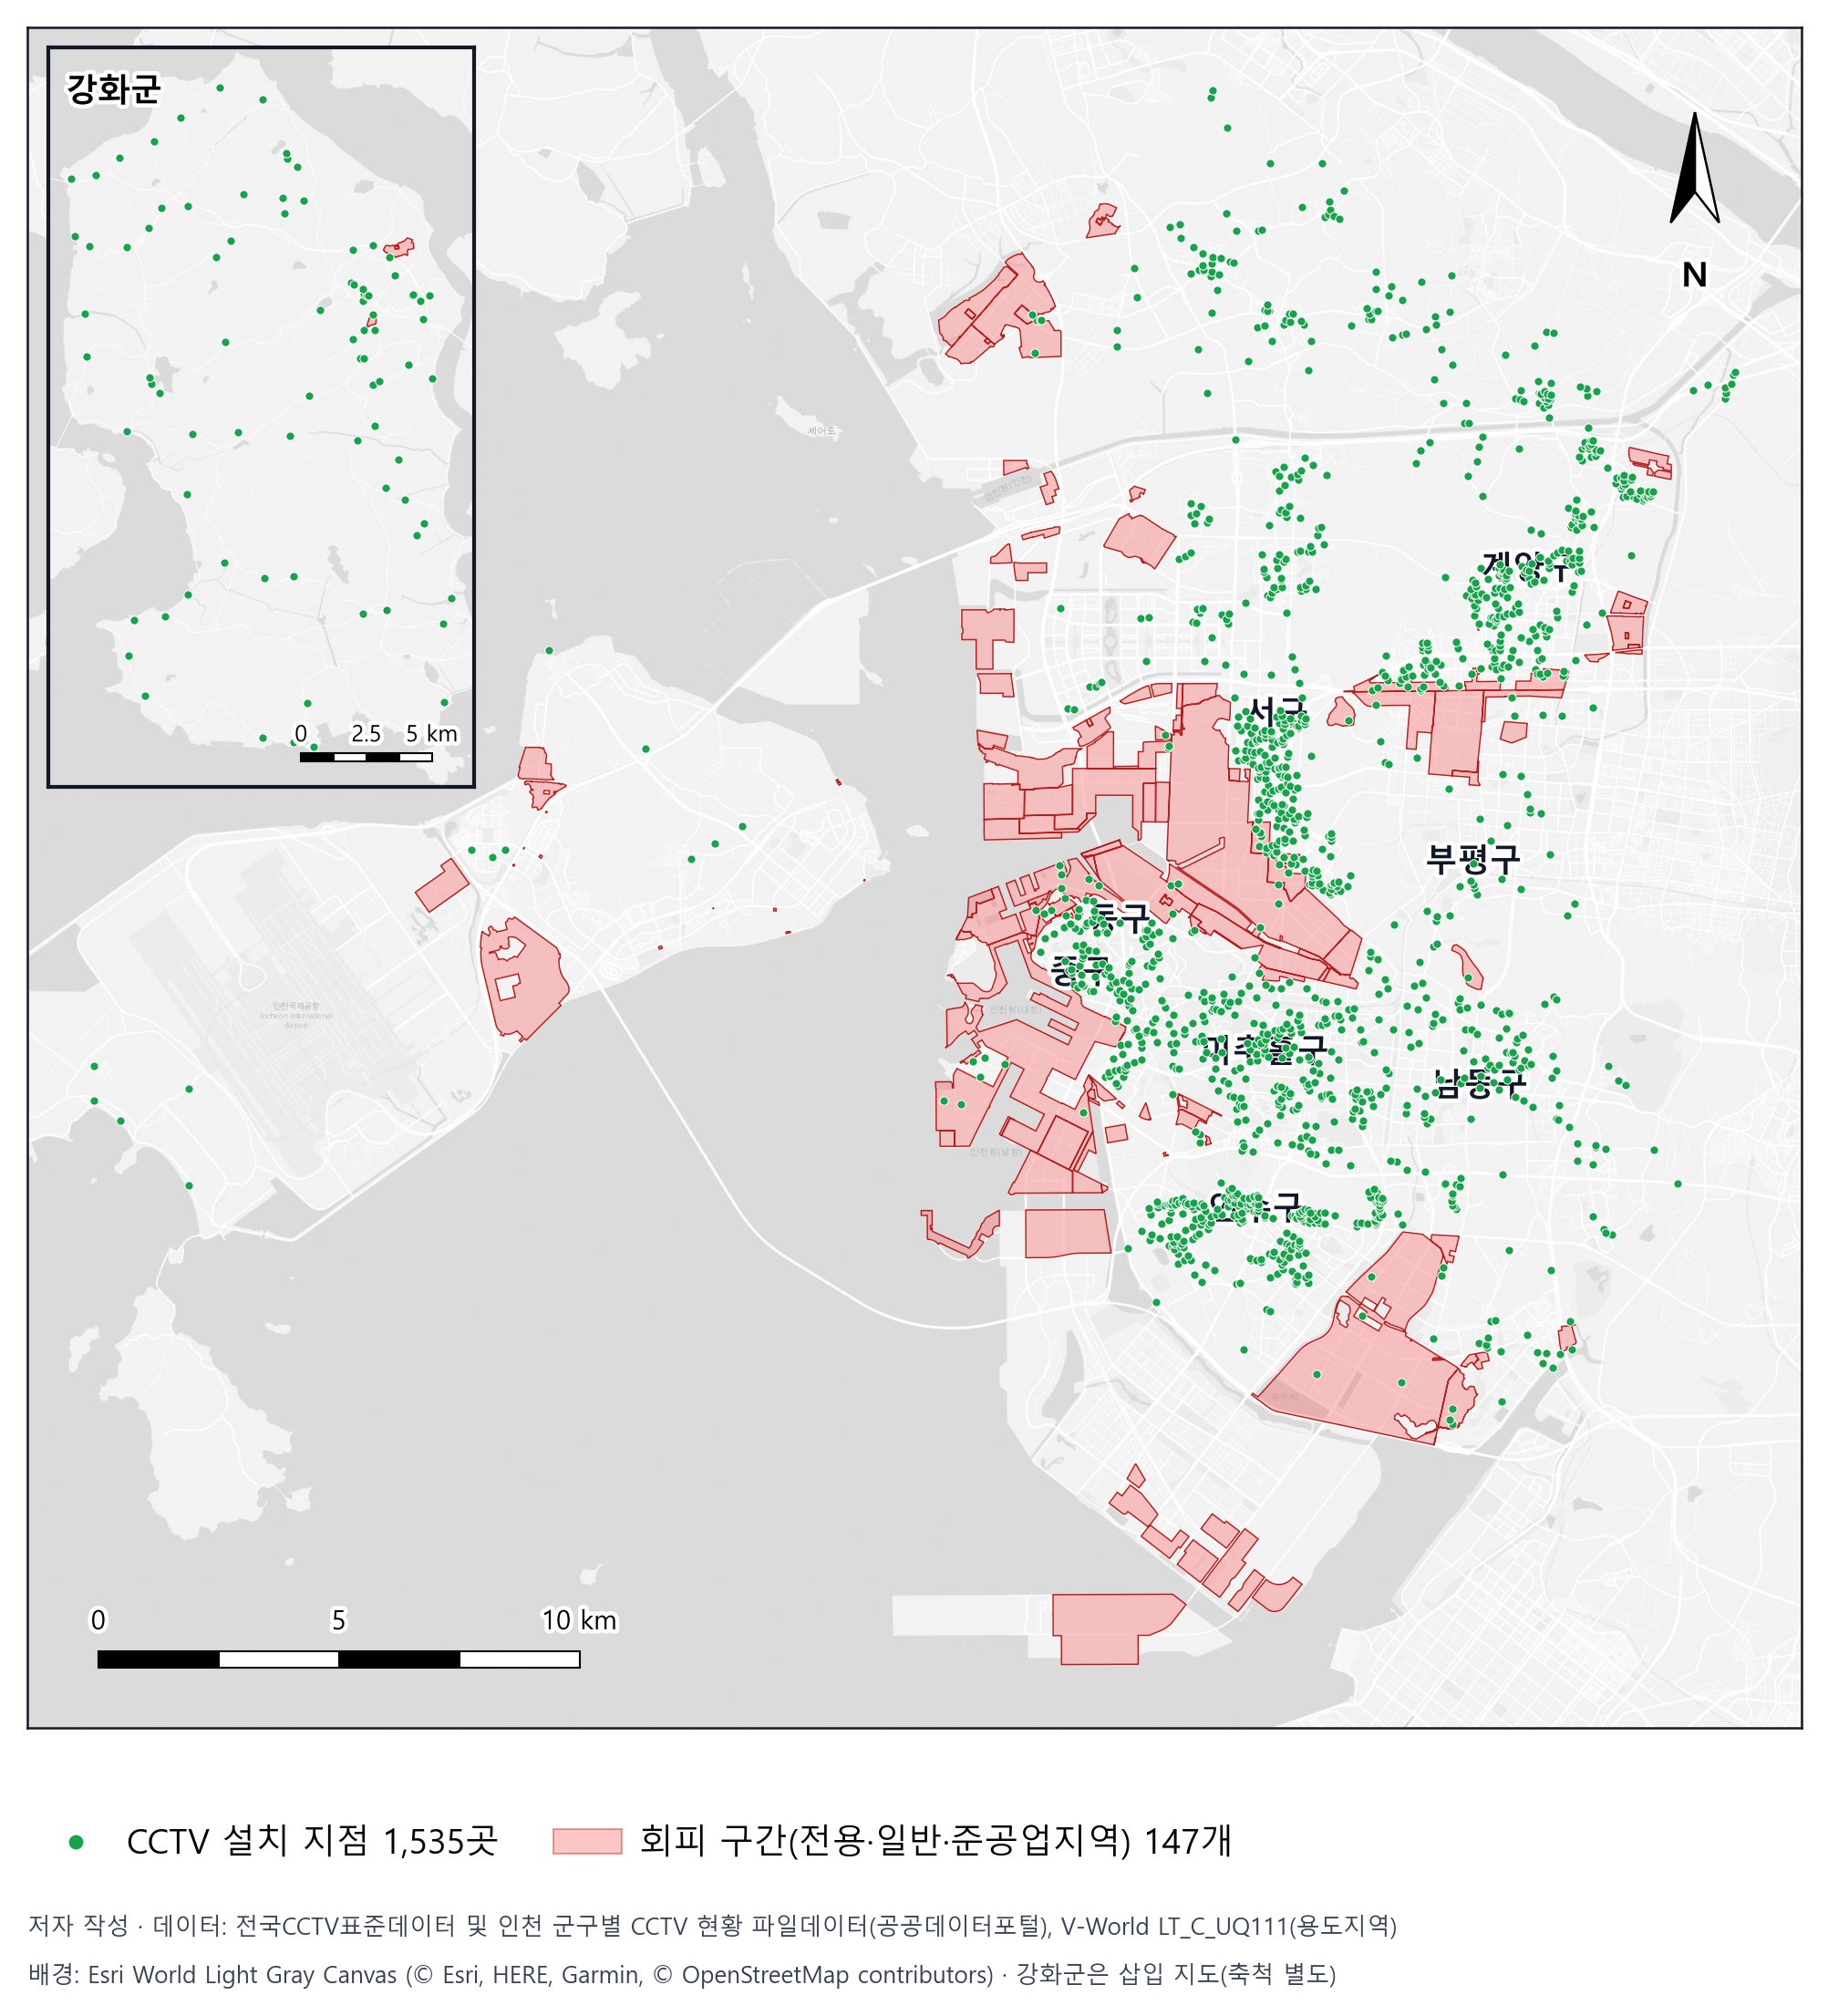

[검증]
  PNG 크기          2070 x 2220px (기대 2070 x 2220)
  그린 CCTV         본 1,449 + 삽입 86 = 1,535 / 데이터 1,535
  그린 회피 구간    147개 (본 144, 삽입 3)
  삽입 지도 위치    upper left, 폭 0.24
  삽입 지도에 가린  본 지도 CCTV 0곳, 회피 구간 0개
  축척 막대         lower left, 10 km (영역 안 CCTV 0곳)
  방위 표시         upper right (영역 안 CCTV 0곳)
  배경 지도         Esri World Light Gray Canvas (© Esri, HERE, Garmin, © OpenStreetMap contributors)

  통과 — CCTV 1,535곳이 모두 보이는가

[저장] C:\Users\User\Documents\GitHub\ploggo-algorithm-test\output_inputmap_v6_261031\fig_slide6_input_map_v6_261031.png


In [11]:
# 셀 8: 그림 조립 → PNG 저장 → 결과 검증

fig = plt.figure(figsize=(FIG_W_IN, FIG_H_IN), dpi=DPI, facecolor="white")
ax = fig.add_axes(MAP_RECT)
n_main = draw_layers(ax, "main", EXT_MAIN, BG_MAIN)
if SHOW_DISTRICT_LABELS:
    draw_district_labels(ax, "main")

# --- 강화군 삽입 지도 ---
n_inset, inset_info = 0, None
if EXT_INSET:
    hid_pts, hid_zone, neg_wf, _, corner, (fx0, fy0, fw, fh) = choose_inset()
    inset_info = dict(corner=corner, width_frac=-neg_wf, hidden_pts=hid_pts, hidden_zones=hid_zone)
    # 축 비율 좌표 → 그림 비율 좌표
    L, B, W, H = MAP_RECT
    ax_in = fig.add_axes([L + fx0 * W, B + fy0 * H, fw * W, fh * H])
    # 삽입 지도 범위를 삽입 축 비율에 맞춘다
    EXT_INSET_FIT = fit_aspect(EXT_INSET, (fh * H * FIG_H_IN) / (fw * W * FIG_W_IN))
    n_inset = draw_layers(ax_in, "inset", EXT_INSET_FIT, BG_INSET)
    for s in ax_in.spines.values():
        s.set_linewidth(1.0)
    # 제목은 점보다 아래 층(zorder 3)에 둔다. 점을 가리지 않기 위함이다
    ax_in.text(0.04, 0.96, "강화군", transform=ax_in.transAxes, fontsize=8.5, fontweight="bold",
               ha="left", va="top", path_effects=_HALO, zorder=3)
    draw_scale_bar(ax_in, EXT_INSET_FIT, corner="lower right", fontsize=6, frac=0.30, margin=0.10)
    # 삽입 지도 뒤로 본 지도 점이 비치지 않도록 축 배경을 불투명하게 둔다
    ax_in.set_zorder(10)
else:
    corner = None

# --- 축척 막대·방위 표시 (삽입 지도와 겹치지 않는 모서리) ---
sb_corner = free_corner(corner, "scale")
na_corner = free_corner(corner, "north")
L_km = draw_scale_bar(ax, EXT_MAIN, corner=sb_corner)
draw_north_arrow(ax, corner=na_corner)

# --- 범례 (지도 아래) ---
handles = [
    Line2D([], [], linestyle="none", marker="o", markersize=4.2, markerfacecolor=CCTV_COLOR,
           markeredgecolor=CCTV_EDGE, markeredgewidth=0.4,
           label=f"CCTV 설치 지점 {N_CCTV:,}곳"),
    Patch(facecolor=ZONE_FACE, alpha=ZONE_ALPHA, edgecolor=ZONE_EDGE, linewidth=0.5,
          label=f"회피 구간(전용·일반·준공업지역) {N_ZONES}개"),
]
fig.legend(handles=handles, loc="lower left", bbox_to_anchor=(MAP_RECT[0], 0.072),
           ncol=2, frameon=False, fontsize=9, handletextpad=0.5, columnspacing=1.6,
           borderaxespad=0)

# --- 출처 ---
credit_1 = f"저자 작성 · 데이터: {CCTV_SOURCE_TEXT}, V-World LT_C_UQ111(용도지역)"
credit_2 = (f"배경: {BASEMAP_CREDIT}" if BASEMAP_CREDIT else "배경 지도 없음") + \
           (" · 강화군은 삽입 지도(축척 별도)" if EXT_INSET else "")
fig.text(MAP_RECT[0], 0.040, credit_1, fontsize=6.2, color="#374151", ha="left", va="bottom")
fig.text(MAP_RECT[0], 0.016, credit_2, fontsize=6.2, color="#374151", ha="left", va="bottom")

fig.savefig(OUT_PNG, dpi=DPI, facecolor="white")      # bbox_inches를 쓰지 않아야 크기가 고정된다
plt.show()

# --- 검증 ---
print("=" * 72)
print("[검증]")
print("=" * 72)
with Image.open(OUT_PNG) as _im:
    _w, _h = _im.size
print(f"  PNG 크기          {_w} x {_h}px (기대 {round(FIG_W_IN*DPI)} x {round(FIG_H_IN*DPI)})")
print(f"  그린 CCTV         본 {n_main:,} + 삽입 {n_inset:,} = {n_main + n_inset:,} / 데이터 {N_CCTV:,}")
print(f"  그린 회피 구간    {N_ZONES}개 (본 {sum(z['region']=='main' for z in zones)}, "
      f"삽입 {sum(z['region']=='inset' for z in zones)})")
if inset_info:
    print(f"  삽입 지도 위치    {inset_info['corner']}, 폭 {inset_info['width_frac']:.2f}")
    print(f"  삽입 지도에 가린  본 지도 CCTV {inset_info['hidden_pts']}곳, 회피 구간 {inset_info['hidden_zones']}개")
_sb_r = (0.03, 0.02, 0.30, 0.07) if "left" in sb_corner else (0.67, 0.02, 0.30, 0.07)
_na_r = (0.02, 0.80, 0.08, 0.17) if "left" in na_corner else (0.90, 0.80, 0.08, 0.17)
_sb_hid = count_hidden(_frac_box_to_data(*_sb_r, EXT_MAIN))[0]
_na_hid = count_hidden(_frac_box_to_data(*_na_r, EXT_MAIN))[0]
print(f"  축척 막대         {sb_corner}, {L_km:g} km (영역 안 CCTV {_sb_hid}곳)")
print(f"  방위 표시         {na_corner} (영역 안 CCTV {_na_hid}곳)")
if _sb_hid or _na_hid:
    print("  [확인] 축척 막대·방위 표시 영역에 점이 있다. 그림에서 가려졌는지 눈으로 확인한다.")
print(f"  배경 지도         {BASEMAP_CREDIT or '없음 (흰 배경)'}")

ok = (n_main + n_inset == N_CCTV) and (not inset_info or inset_info["hidden_pts"] == 0)
print(f"\n  {'통과' if ok else '확인 필요'} — CCTV {N_CCTV:,}곳이 모두 보이는가")
if inset_info and inset_info["hidden_pts"] > 0:
    print("  [조치] INSET_WIDTH_FRACS에 더 작은 폭을 넣거나 INSET_CORNER를 직접 지정한다.")
print(f"\n[저장] {OUT_PNG.resolve()}")


## 참고 — 자주 바꾸는 설정 (셀 2)

| 설정 | 기본값 | 바꾸는 경우 |
| --- | --- | --- |
| `BASEMAP_ORDER` | V-World → Esri → CARTO | 특정 배경을 강제할 때 하나만 남긴다 |
| `TILE_ZOOM_MAIN` | 자동 | 배경 지명 글자를 키우려면 12, 더 세밀하게는 14 |
| `TILE_FADE` | 0.25 | 배경이 진하면 올리고, 흐리면 내린다 |
| `INSET_CORNER` | auto | 위치를 직접 정할 때 |
| `SHOW_DISTRICT_LABELS` | True | 배경 지도의 지명과 겹쳐 복잡하면 False |
| `CCTV_SOURCE_TEXT` | 자동 | 셀 4 판단 후 직접 확정 |

배경을 바꿔 다시 그릴 때는 셀 6부터 다시 실행하면 된다. 타일은 `tile_cache/`에 남아 있으므로 같은 배경은 다시 받지 않는다.
